# 03. Model comparison: which model, and can we trust the scores?

**Question.** Does a more complex model beat a simple baseline, are the scores inflated by duplicates, and what is left without the suspicious variables?

**Protocol.** Every model is scored on **exactly the same folds**: stratified (same churn share in each fold) and grouped (identical rows never straddle train and test). Metrics are threshold-free and suited to an imbalanced target (15.7% churners):

- **PR-AUC**: a random model scores 0.157.
- **Recall in the top 20%**: share of all churners found by contacting the 20% highest-scored customers.
- **Lift in the top 20%**: that recall divided by 0.2 (random = 1).

Accuracy is not used: "nobody churns" already scores 84.3%.

*The three experiments below take a few minutes to run.*

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image
from sklearn.model_selection import StratifiedKFold

from churn.compare import MODEL_NAMES, SUSPECT_FEATURES, evaluate
from churn.data import load_config, load_raw
from churn.features import build_features, duplicate_groups, split_xy

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

seed = load_config()["project"]["seed"]
df = build_features(load_raw())
X, y = split_xy(df)
groups = duplicate_groups(df).to_numpy()
active_mask = (X["is_inactive"] == 0).to_numpy()
print(X.shape, f"churn rate {y.mean():.3f}")

300 fully duplicated rows found (kept, to be reviewed in EDA)


(3150, 12) churn rate 0.157


## A. Four models, same folds

Hyperparameters here are reasonable hand-picked values (tuning comes later).

In [2]:
results = pd.DataFrame({m: evaluate(m, X, y, groups, active_mask, seed) for m in MODEL_NAMES}).T
results.round(3)

,roc_auc,pr_auc,recall_top20,lift_top20,active_pr_auc,active_lift_top20
logistic,0.939,0.778,0.792,3.960,0.738,3.92
svm_rbf,0.967,0.864,0.887,4.434,0.851,4.76
random_forest,0.982,0.907,0.939,4.696,0.927,4.92
hist_gradient_boosting,0.980,0.916,0.917,4.586,0.918,4.88


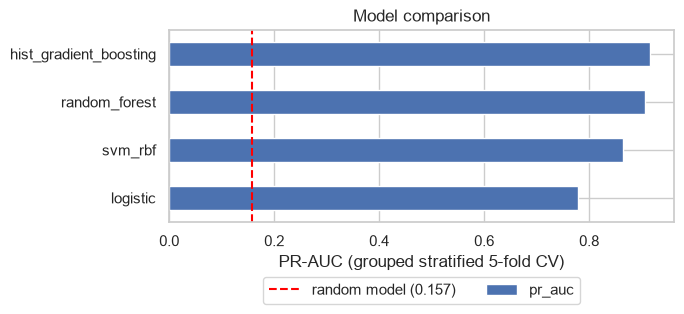

In [8]:
ax = results["pr_auc"].sort_values().plot.barh(figsize=(7, 3.5), color="#4C72B0")
ax.axvline(y.mean(), color="red", linestyle="--", label=f"random model ({y.mean():.3f})")
ax.set_xlabel("PR-AUC (grouped stratified 5-fold CV)")
ax.set_title("Model comparison")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png", dpi=150)
plt.show()

**Reading.** The tree-based models beat the logistic regression by far more than the fold-to-fold noise (about 0.03 PR-AUC). There are non-linearities and interactions a linear model cannot capture. Random forest and gradient boosting are statistically tied here. The SVM is dominated and was dropped from later steps.

## B. Were the scores inflated by duplicate rows?

The dataset contains 300 exact duplicate rows (9.5%). With a naive split, a customer can be in train while his twin is in test, which would flatter flexible models. We compare the grouped split with a naive one.

In [4]:
naive = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
rows = {}
for m in MODEL_NAMES:
    n = evaluate(m, X, y, groups, active_mask, seed, cv=naive)
    rows[m] = {"pr_auc_grouped": results.loc[m, "pr_auc"], "pr_auc_naive": n["pr_auc"]}
leak = pd.DataFrame(rows).T
leak["gap"] = leak["pr_auc_naive"] - leak["pr_auc_grouped"]
leak.round(3)

,pr_auc_grouped,pr_auc_naive,gap
logistic,0.778,0.777,-0.001
svm_rbf,0.864,0.867,0.003
random_forest,0.907,0.907,-0.001
hist_gradient_boosting,0.916,0.919,0.003


**Reading.** The gap is within a few thousandths for every model, so duplicates did **not** inflate the scores. Grouped splitting is kept anyway: it costs nothing and removes the risk by design.

## C. Ablation: what if `complains` and `is_inactive` are consequences of leaving?

The dataset does not say when these two variables were measured. If they were recorded late, a model using them partly "recognises customers who already left". We remove them and look at what survives.

In [5]:
X_abl = X.drop(columns=SUSPECT_FEATURES)
abl = pd.DataFrame({m: evaluate(m, X_abl, y, groups, active_mask, seed) for m in MODEL_NAMES}).T
print("Without complains and is_inactive:")
display(abl.round(3))
print("PR-AUC change versus the full model:")
display((abl["pr_auc"] - results["pr_auc"]).round(3).to_frame("pr_auc_change"))

Without complains and is_inactive:


,roc_auc,pr_auc,recall_top20,lift_top20,active_pr_auc,active_lift_top20
logistic,0.885,0.563,0.675,3.374,0.345,3.60
svm_rbf,0.934,0.762,0.804,4.020,0.654,4.28
random_forest,0.972,0.842,0.915,4.575,0.767,4.88
hist_gradient_boosting,0.962,0.836,0.873,4.364,0.789,4.60


PR-AUC change versus the full model:


,pr_auc_change
logistic,-0.215
svm_rbf,-0.103
random_forest,-0.065
hist_gradient_boosting,-0.080


**Reading.** The logistic regression collapses (PR-AUC -0.215: it leaned heavily on these two variables) and the SVM loses 0.10, while the tree-based models lose 0.065 to 0.080 and keep most of their performance (PR-AUC about 0.84 before tuning). Usage therefore carries a large part of the signal, but the two variables still add something. This justifies delivering **two versions** of the model: a *full* one, and an *early-warning* one that stays valid in the worst case.

## D. Tuning with nested cross-validation

Tuning on the same folds that score the model gives optimistic numbers. We use **nested CV**: an inner loop picks hyperparameters on training data only, an outer loop scores the tuned model on unseen folds.

These values come from `python -m churn.tune` (several minutes to run, so reported rather than recomputed here):

In [6]:
tuned = pd.DataFrame(
    {
        "roc_auc": [0.985, 0.987, 0.977, 0.978],
        "pr_auc": [0.932, 0.947, 0.867, 0.906],
        "pr_auc_std_across_folds": [0.031, 0.028, 0.074, 0.039],
        "recall_top20": [0.953, 0.951, 0.949, 0.927],
    },
    index=pd.MultiIndex.from_tuples(
        [("full", "random_forest"), ("full", "gradient_boosting"),
         ("early_warning", "random_forest"), ("early_warning", "gradient_boosting")]
    ),
)
tuned

roc_auc  pr_auc  pr_auc_std_across_folds  \
full          random_forest        0.985   0.932                    0.031   
              gradient_boosting    0.987   0.947                    0.028   
early_warning random_forest        0.977   0.867                    0.074   
              gradient_boosting    0.978   0.906                    0.039   

                                 recall_top20  
full          random_forest             0.953  
              gradient_boosting         0.951  
early_warning random_forest             0.949  
              gradient_boosting         0.927

**Decision: gradient boosting for both versions.** It has the best PR-AUC in both and is more stable in the early-warning setting (fold standard deviation 0.039 against 0.074 for the random forest). On still-active customers, the real target of a campaign, it is clearly better in the early-warning version (PR-AUC 0.854 against 0.811, from `tune.py`) and tied in the full version (0.926 against 0.932). In the full version the two models are tied within noise, so the choice there is one of consistency.

## E. From scores to a decision

A score is not a decision. The campaign rule contacts a customer when

`churn probability x offer success rate x customer value - offer cost > 0`

with assumptions set in `config/config.yaml` (cost 10, success 30%; units of `customer_value`, which is undocumented). Computed on out-of-fold scores of the tuned gradient boosting (from `python -m churn.evaluate`, seed 42):

| Policy | Customers contacted | Churners reached | Net profit |
|---|---|---|---|
| Contact everyone | 100% | 100% | -12,966 |
| Top 19% by probability (k chosen with hindsight) | 19% | 94% | +11,330 |
| **Expected-gain rule, full model** (applicable) | **12%** | **66%** | **+13,054** |
| Expected-gain rule, early-warning model | 13% | 63% | +12,004 |

The expected-gain rule beats ranking by probability alone because it also uses each customer's value. The hindsight row picks k using the true outcomes, so it is a reference, not a deployable rule.

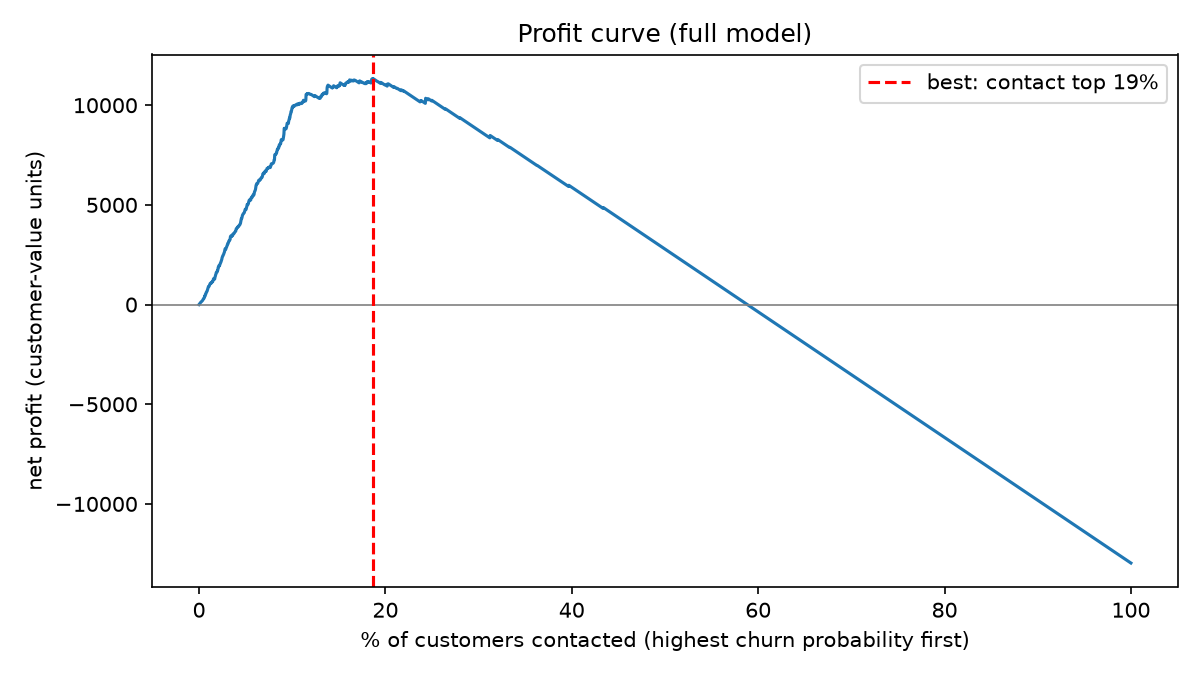

In [7]:
Image("../reports/figures/profit_curve_full.png")

## Conclusions

1. A tuned **gradient boosting** reaches a PR-AUC of about 0.95 in the full version (random: 0.16) and finds about 95% of churners in the top 20% of scores.
2. Scores are **not inflated** by duplicate rows.
3. Without the two possibly-late variables, the tuned gradient boosting keeps a PR-AUC of about 0.91 (untuned models: about 0.84), so most of the signal comes from usage.
4. Targeting about **12% of customers** with the expected-gain rule is profitable, while contacting everyone loses money. The profit stays positive across the whole cost and success-rate grid tested (see `evaluate.py`), but in the worst case (10% success, cost 20) it is small (+863, with only 2% of customers contacted), and the assumptions themselves are invented.

Limits: tuned values sit near the edge of the search grid, business assumptions are not measured, and with only 125 still-active churners the active-only metrics are noisy.